<a href="https://colab.research.google.com/github/nashlypilar-collab/PROYECTO-ENTRE-GRUPAL-/blob/main/Proyecto_1_Dataset_Sueno_Prediccion_Fatiga.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto 1 — Dataset del sueño
## Predicción de la fatiga del día siguiente

**Objetivo:** El proyecto busca estimar la fatiga que una persona reportará al día siguiente a partir de información sobre sus características personales, hábitos digitales y mediciones de la noche de sueño anterior.

**Pregunta de negocio:** ¿Qué tan bien podemos predecir la puntuación de fatiga del día siguiente a partir de la información disponible al despertar y cuáles son los factores más relevantes para esa predicción?

**Target:** `La variable objetivo es next_day_fatigue_score, una variable numérica continua que representa la puntuación de fatiga que se busca predecir, que tiene una puntuación que va de 1 a 10.

## 0. Librerías

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_validate, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)

## 1. Carga de la base

In [2]:
try:
    from google.colab import files
    uploaded = files.upload()
    csv_name = next((name for name in uploaded if name.lower().endswith('.csv')), None)
    if csv_name is None:
        raise ValueError("No se cargó ningún archivo CSV.")
    df = pd.read_csv(csv_name)
except ImportError:
    # Alternativa para ejecutar fuera de Colab: cambia la ruta por la ubicación del CSV.
    csv_name = "sleep_debt_screen_time(1).csv"
    df = pd.read_csv(csv_name)

print(f"Archivo: {csv_name}")
print(f"Dimensiones: {df.shape[0]} filas y {df.shape[1]} columnas")
df.head()

Saving sleep_debt_screen_time.csv to sleep_debt_screen_time.csv
Archivo: sleep_debt_screen_time.csv
Dimensiones: 8500 filas y 23 columnas


,user_id,age,gender,chronotype,occupation,bedtime_hour,screen_time_before_bed_min,primary_app_category,screen_brightness_pct,blue_light_filter_on,caffeine_intake_mg,caffeine_last_hour,physical_activity_min,room_temperature_f,ambient_noise_db,sleep_onset_latency_min,total_sleep_hours,rem_sleep_pct,deep_sleep_pct,awakenings_count,sleep_efficiency_pct,next_day_fatigue_score,sleep_debt_category
0,1,32,Female,Intermediate,Student,23.94,102,Social Media,100,False,264,21.5,73,73.5,32.6,60.3,5.67,15.2,13.5,11,63.7,8.85,Moderate
1,2,26,Female,Intermediate,Student,0.06,14,Short-Form Video,87,True,18,12.6,25,66.8,44.3,24.5,7.42,16.9,22.3,1,92.9,2.98,No Debt
2,3,34,Male,Night Owl,Professional,1.48,58,Messaging,76,True,62,16.5,48,68.0,45.6,21.9,6.98,20.2,18.5,2,84.6,3.90,Mild
3,4,43,Female,Intermediate,Professional,22.42,48,Social Media,56,False,42,18.9,9,72.3,42.3,34.5,7.67,14.4,17.3,6,79.9,4.81,No Debt
4,5,25,Male,Early Bird,Professional,22.43,29,Streaming,96,True,78,16.3,5,80.1,10.0,37.4,6.31,16.6,16.1,0,89.3,3.88,Mild


## 2. Reconocimiento y calidad de los datos

In [3]:
display(df.head())
print("\nTipos de datos:")
display(df.dtypes.rename("tipo").to_frame())
print("\nResumen de nulos:")
display(df.isna().sum().rename("nulos").to_frame().sort_values("nulos", ascending=False))
print("Filas duplicadas completas:", df.duplicated().sum())
print("\nResumen numérico:")
display(df.describe().T)

,user_id,age,gender,chronotype,occupation,bedtime_hour,screen_time_before_bed_min,primary_app_category,screen_brightness_pct,blue_light_filter_on,caffeine_intake_mg,caffeine_last_hour,physical_activity_min,room_temperature_f,ambient_noise_db,sleep_onset_latency_min,total_sleep_hours,rem_sleep_pct,deep_sleep_pct,awakenings_count,sleep_efficiency_pct,next_day_fatigue_score,sleep_debt_category
0,1,32,Female,Intermediate,Student,23.94,102,Social Media,100,False,264,21.5,73,73.5,32.6,60.3,5.67,15.2,13.5,11,63.7,8.85,Moderate
1,2,26,Female,Intermediate,Student,0.06,14,Short-Form Video,87,True,18,12.6,25,66.8,44.3,24.5,7.42,16.9,22.3,1,92.9,2.98,No Debt
2,3,34,Male,Night Owl,Professional,1.48,58,Messaging,76,True,62,16.5,48,68.0,45.6,21.9,6.98,20.2,18.5,2,84.6,3.90,Mild
3,4,43,Female,Intermediate,Professional,22.42,48,Social Media,56,False,42,18.9,9,72.3,42.3,34.5,7.67,14.4,17.3,6,79.9,4.81,No Debt
4,5,25,Male,Early Bird,Professional,22.43,29,Streaming,96,True,78,16.3,5,80.1,10.0,37.4,6.31,16.6,16.1,0,89.3,3.88,Mild



Tipos de datos:


,tipo
user_id,int64
age,int64
gender,object
chronotype,object
occupation,object
bedtime_hour,float64
screen_time_before_bed_min,int64
primary_app_category,object
screen_brightness_pct,int64
blue_light_filter_on,bool



Resumen de nulos:


,nulos
user_id,0
age,0
gender,0
chronotype,0
occupation,0
bedtime_hour,0
screen_time_before_bed_min,0
primary_app_category,0
screen_brightness_pct,0
blue_light_filter_on,0


Filas duplicadas completas: 0

Resumen numérico:


,count,mean,std,min,25%,50%,75%,max
user_id,8500.0,4250.500000,2453.882977,1.00,2125.75,4250.50,6375.25,8500.00
age,8500.0,28.099647,9.007551,16.00,21.00,27.00,34.00,65.00
bedtime_hour,8500.0,13.883186,10.836579,0.00,1.09,22.20,23.15,24.00
screen_time_before_bed_min,8500.0,53.744118,35.349292,5.00,29.00,45.00,68.00,240.00
screen_brightness_pct,8500.0,68.770235,18.923090,5.00,56.00,69.00,83.00,100.00
caffeine_intake_mg,8500.0,79.650000,78.348824,0.00,22.00,55.50,113.00,500.00
caffeine_last_hour,8500.0,15.905871,3.844196,6.00,13.20,16.00,18.70,23.00
physical_activity_min,8500.0,29.761882,30.000228,0.00,8.00,20.00,42.00,180.00
room_temperature_f,8500.0,70.083506,3.962443,58.00,67.40,70.10,72.70,82.00
ambient_noise_db,8500.0,34.972753,10.011726,10.00,28.20,35.00,41.50,70.00


In [4]:
# Revisión de cardinalidad y categorías en variables de texto
cat_cols_all = df.select_dtypes(include=["object", "bool", "category"]).columns
cardinalidad = pd.DataFrame({
    "valores_unicos": df[cat_cols_all].nunique(dropna=False),
    "ejemplos": [df[c].dropna().unique()[:8].tolist() for c in cat_cols_all]
})
display(cardinalidad)

,valores_unicos,ejemplos
gender,3,"[Female, Male, Non-Binary]"
chronotype,3,"[Intermediate, Night Owl, Early Bird]"
occupation,5,"[Student, Professional, Retired, Unemployed, F..."
primary_app_category,7,"[Social Media, Short-Form Video, Messaging, St..."
blue_light_filter_on,2,"[False, True]"
sleep_debt_category,4,"[Moderate, No Debt, Mild, Severe]"


## 3. EDA — variable objetivo

count    8500.000000
mean        4.549893
std         0.954115
min         1.070000
25%         3.890000
50%         4.520000
75%         5.180000
max         8.850000
Name: next_day_fatigue_score, dtype: float64
Nulos en target: 0


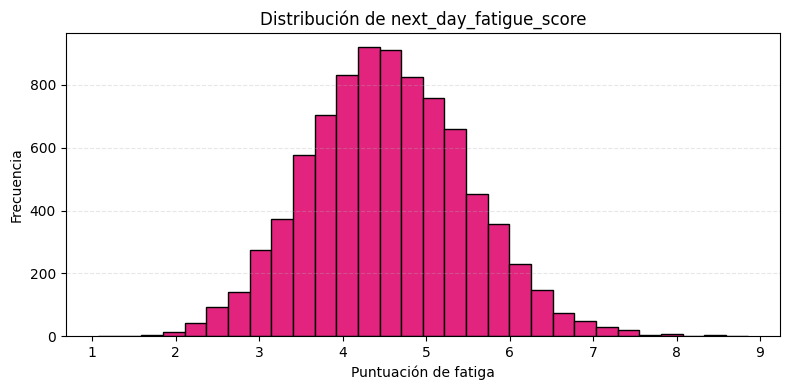

In [25]:
TARGET = "next_day_fatigue_score"
if TARGET not in df.columns:
    raise KeyError(f"No se encontró la variable objetivo {TARGET!r} en el CSV.")

y_eda = pd.to_numeric(df[TARGET], errors="coerce")
print(y_eda.describe())
print("Nulos en target:", y_eda.isna().sum())

fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(
    y_eda.dropna(),
    bins=30,
    color=plt.cm.PuRd(0.65),
    edgecolor="black"
)

ax.set_title("Distribución de next_day_fatigue_score")
ax.set_xlabel("Puntuación de fatiga")
ax.set_ylabel("Frecuencia")
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

## 4. EDA — variables predictoras y relaciones

✦ CORRELACIÓN DE LAS VARIABLES CON LA FATIGA ✦


,Correlación con la fatiga
total_sleep_hours,-0.689
sleep_efficiency_pct,-0.537
rem_sleep_pct,-0.337
deep_sleep_pct,-0.191
bedtime_hour,-0.132
room_temperature_f,0.011
physical_activity_min,0.017
ambient_noise_db,0.068
caffeine_last_hour,0.131
screen_brightness_pct,0.176


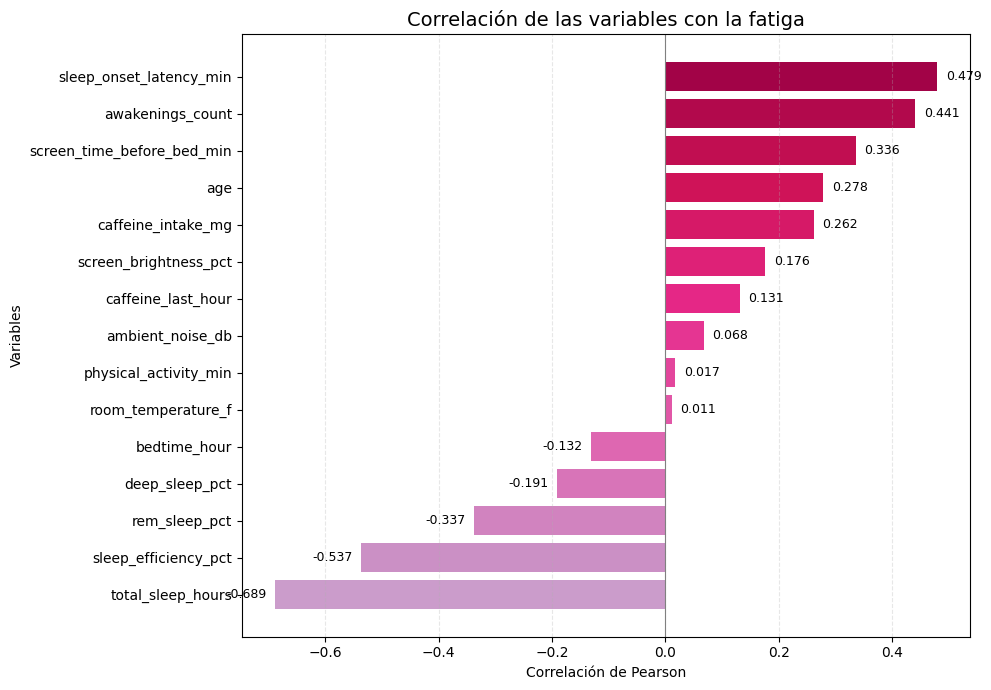

In [6]:
# Seleccionar las variables numéricas
numeric_eda = df.select_dtypes(include=np.number).columns.tolist()

# Excluir identificadores y variable objetivo de las predictoras
for col in ["user_id", TARGET]:
    if col in numeric_eda:
        numeric_eda.remove(col)

# Calcular correlaciones con la variable objetivo
correlaciones = (
    df[numeric_eda + [TARGET]]
    .corr(numeric_only=True)[TARGET]
    .drop(TARGET)
    .sort_values()
)

# Mostrar tabla de correlaciones
print("\033[95m✦ CORRELACIÓN DE LAS VARIABLES CON LA FATIGA ✦\033[0m")

display(
    correlaciones.to_frame(name="Correlación con la fatiga")
    .style
    .format("{:.3f}")
    .background_gradient(cmap="PuRd")
)

# Crear gráfica de correlaciones
fig, ax = plt.subplots(figsize=(10, 7))

colores = plt.cm.PuRd(
    np.linspace(0.35, 0.85, len(correlaciones))
)

barras = ax.barh(
    correlaciones.index,
    correlaciones.values,
    color=colores
)

ax.set_title("Correlación de las variables con la fatiga", fontsize=14)
ax.set_xlabel("Correlación de Pearson")
ax.set_ylabel("Variables")
ax.axvline(0, color="gray", linewidth=0.8)

# Mostrar los valores en cada barra
for barra in barras:
    valor = barra.get_width()
    posicion = valor + 0.015 if valor >= 0 else valor - 0.015

    ax.text(
        posicion,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:.3f}",
        va="center",
        ha="left" if valor >= 0 else "right",
        fontsize=9
    )

ax.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

### Conclusiones

Los resultados evidencian que la calidad y duración del sueño son los factores que presentan mayor asociación con la fatiga del día siguiente. Dormir más horas y tener una mejor eficiencia del sueño se relaciona con menores niveles de fatiga, mientras que tardar más en conciliar el sueño, despertarse durante la noche y pasar más tiempo frente a pantallas antes de dormir se relaciona con mayores niveles de fatiga. Por tanto, estas variables se perfilan como las más relevantes para desarrollar el modelo predictivo.

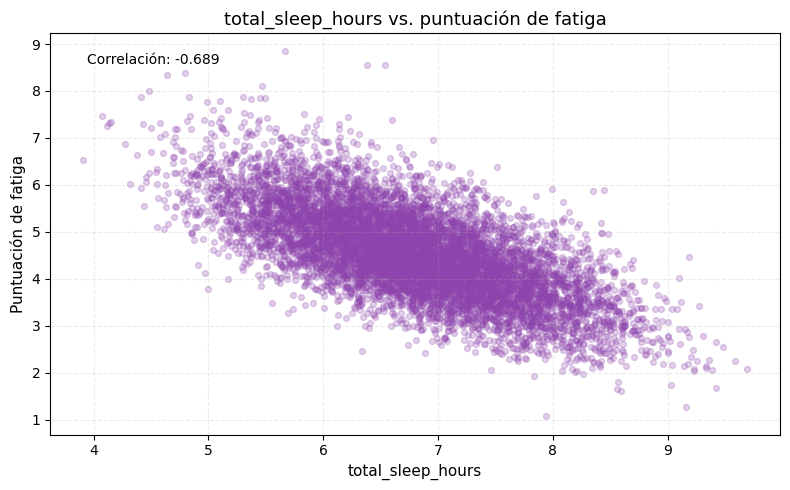

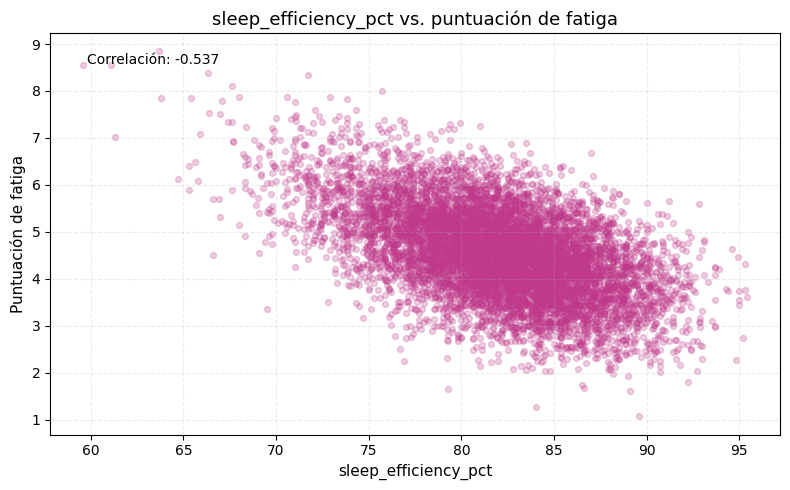

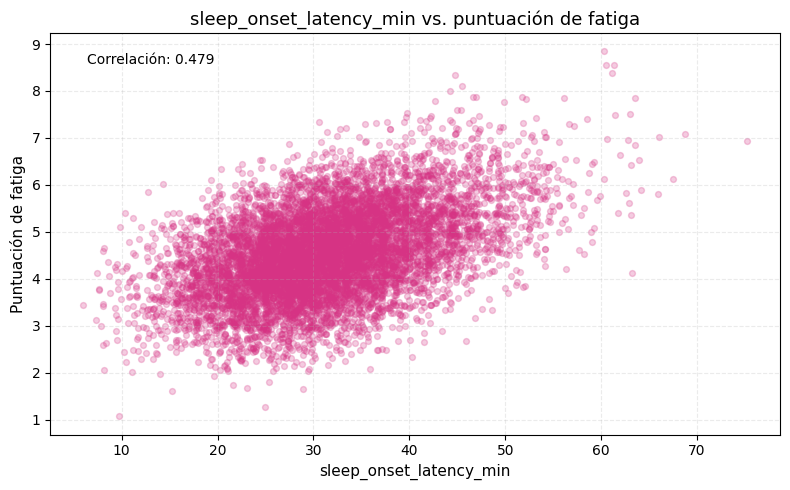

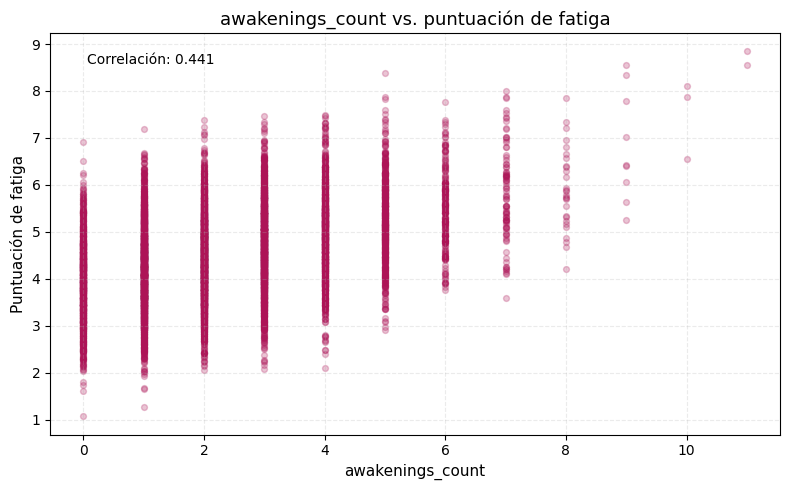

In [7]:
# Diagramas de dispersión de las variables más relacionadas con la fatiga

top_corr = correlaciones.abs().sort_values(ascending=False).head(4).index.tolist()

colores = ["#8E44AD", "#C0398B", "#D63384", "#AD1457"]

for i, col in enumerate(top_corr):
    fig, ax = plt.subplots(figsize=(8, 5))

    ax.scatter(
        df[col],
        df[TARGET],
        color=colores[i],
        alpha=0.25,
        s=18
    )

    valor_corr = correlaciones[col]

    ax.set_title(
        f"{col} vs. puntuación de fatiga",
        fontsize=13
    )

    ax.set_xlabel(col, fontsize=11)
    ax.set_ylabel("Puntuación de fatiga", fontsize=11)

    ax.text(
        0.05, 0.95,
        f"Correlación: {valor_corr:.3f}",
        transform=ax.transAxes,
        va="top",
        fontsize=10
    )

    ax.grid(axis="both", linestyle="--", alpha=0.25)

    plt.tight_layout()
    plt.show()



### Conclusión

Los diagramas evidencian que la duración y eficiencia del sueño presentan una relación inversa con la fatiga, mientras que el tiempo necesario para conciliar el sueño y la cantidad de despertares muestran una relación directa. Esto refuerza la importancia de las características del descanso como variables relevantes para predecir la fatiga del día siguiente.

,count,mean,median,std
gender,,,,
Non-Binary,346,4.63,4.69,1.02
Female,4106,4.55,4.52,0.95
Male,4048,4.55,4.52,0.95


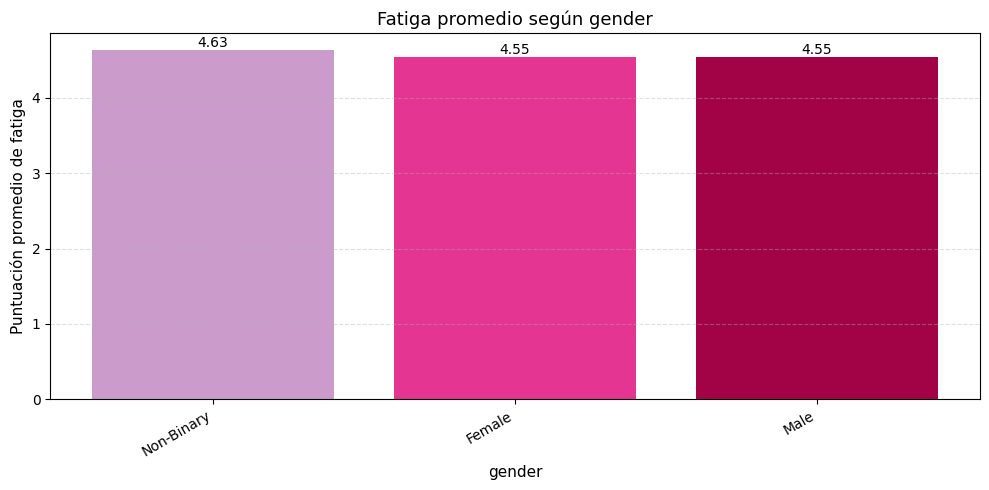

,count,mean,median,std
chronotype,,,,
Night Owl,2967,4.71,4.69,0.94
Intermediate,3466,4.52,4.49,0.96
Early Bird,2067,4.37,4.36,0.94


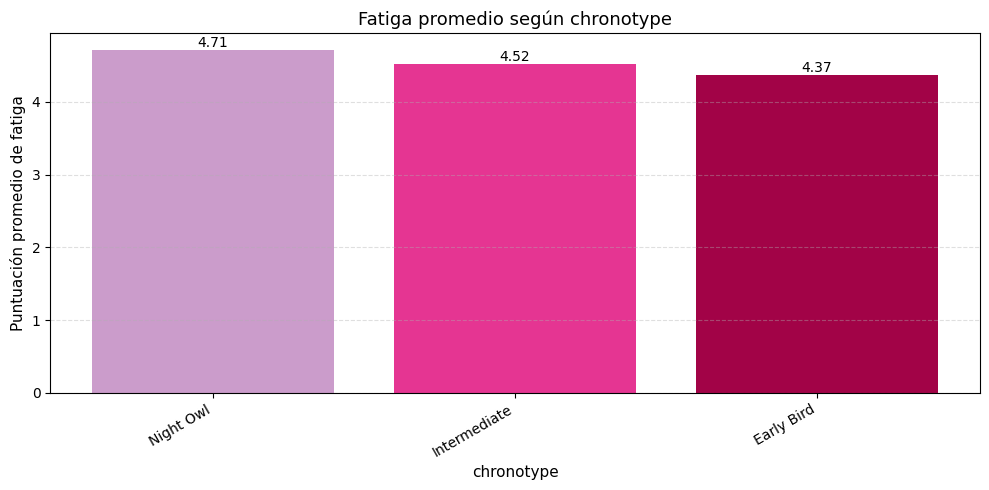

,count,mean,median,std
occupation,,,,
Retired,847,4.61,4.55,0.92
Unemployed,829,4.56,4.54,0.97
Student,2588,4.55,4.54,0.97
Professional,2980,4.53,4.51,0.94
Freelancer,1256,4.53,4.49,0.96


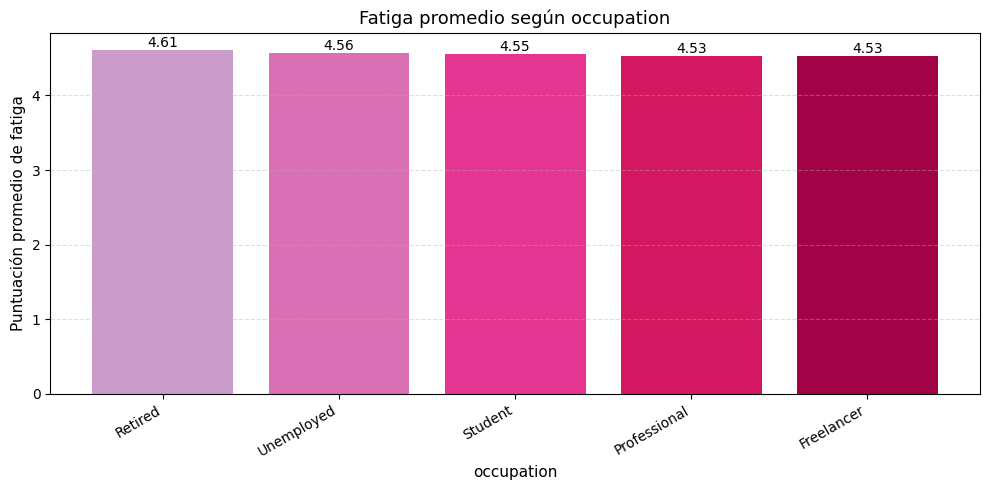

,count,mean,median,std
primary_app_category,,,,
Short-Form Video,2468,4.75,4.72,0.96
Gaming,882,4.67,4.62,0.94
Social Media,1834,4.61,4.56,0.93
Messaging,753,4.46,4.44,0.92
News,659,4.42,4.42,0.95
Streaming,1193,4.40,4.34,0.91
E-Reading,711,4.04,3.97,0.88


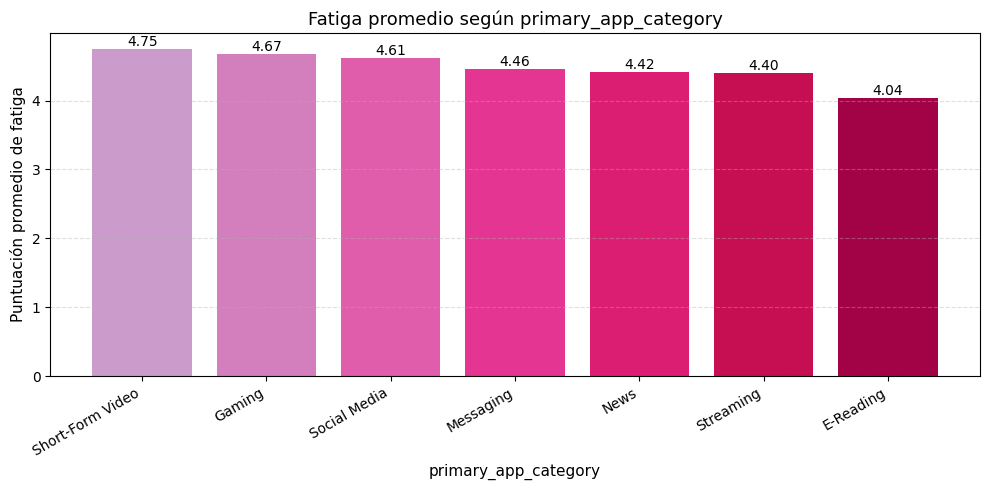

,count,mean,median,std
blue_light_filter_on,,,,
False,5563,4.64,4.62,0.97
True,2937,4.38,4.36,0.90


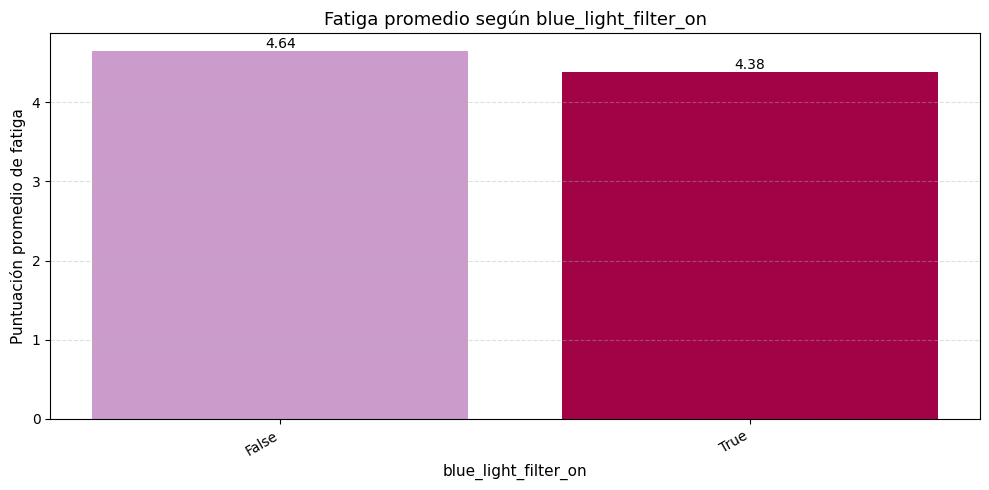

In [26]:
# Distribución de las variables categóricas disponibles
cat_eda = df.select_dtypes(include=["object", "bool", "category"]).columns.tolist()
cat_eda = [col for col in cat_eda if col != "sleep_debt_category"]

for col in cat_eda:
    resumen_cat = df.groupby(col, dropna=False)[TARGET].agg(
        ["count", "mean", "median", "std"]
    ).sort_values("mean", ascending=False)

    display(resumen_cat.round(2))

    fig, ax = plt.subplots(figsize=(10, 5))

    colores = plt.cm.PuRd(
        np.linspace(0.35, 0.85, len(resumen_cat))
    )

    barras = ax.bar(
        resumen_cat.index.astype(str),
        resumen_cat["mean"],
        color=colores
    )

    ax.set_title(f"Fatiga promedio según {col}", fontsize=13)
    ax.set_xlabel(col, fontsize=11)
    ax.set_ylabel("Puntuación promedio de fatiga", fontsize=11)
    ax.set_xticklabels(resumen_cat.index.astype(str), rotation=30, ha="right")

    for barra in barras:
        altura = barra.get_height()
        ax.annotate(
            f"{altura:.2f}",
            (barra.get_x() + barra.get_width() / 2, altura),
            ha="center",
            va="bottom",
            fontsize=10
        )

    ax.grid(axis="y", linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()

### Conclusiones

El análisis exploratorio de las variables categóricas permitió identificar diferencias en el comportamiento de la fatiga entre los distintos grupos del conjunto de datos. Se observa que el cronotipo nocturno y el uso de aplicaciones de videos cortos presentan los mayores promedios de fatiga, mientras que el uso de aplicaciones de lectura electrónica presenta el menor. Por su parte, la ocupación muestra promedios similares entre sus categorías. Estos hallazgos permiten reconocer posibles patrones y seleccionar variables que podrían aportar información al modelo de predicción. Sin embargo, estas diferencias representan asociaciones y no relaciones de causalidad.

## 5. Preparación y selección inicial de variables

Se excluyen `user_id`, `sleep_debt_category` y el target de las predictoras. Para el escenario de predicción al despertar.

In [9]:
excluded_cols = ["user_id", "sleep_debt_category", TARGET]
X = df.drop(columns=[c for c in excluded_cols if c in df.columns]).copy()
y = pd.to_numeric(df[TARGET], errors="coerce")

# Quitar únicamente filas cuyo target no se pueda usar; no imputamos la respuesta.
valid_target = y.notna()
X = X.loc[valid_target].copy()
y = y.loc[valid_target].copy()

# Separar columnas según tipo; los booleanos se tratan como categóricos.
cat_cols = X.select_dtypes(include=["object", "bool", "category"]).columns.tolist()
num_cols = X.select_dtypes(include=np.number).columns.tolist()

print("Predictoras numéricas:", num_cols)
print("Predictoras categóricas:", cat_cols)
print("Registros útiles:", len(X))
print("Nulos en X:", int(X.isna().sum().sum()))

Predictoras numéricas: ['age', 'bedtime_hour', 'screen_time_before_bed_min', 'screen_brightness_pct', 'caffeine_intake_mg', 'caffeine_last_hour', 'physical_activity_min', 'room_temperature_f', 'ambient_noise_db', 'sleep_onset_latency_min', 'total_sleep_hours', 'rem_sleep_pct', 'deep_sleep_pct', 'awakenings_count', 'sleep_efficiency_pct']
Predictoras categóricas: ['gender', 'chronotype', 'occupation', 'primary_app_category', 'blue_light_filter_on']
Registros útiles: 8500
Nulos en X: 0


## 6. Separación entrenamiento/prueba y pipeline de preparación

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

num_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
cat_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)

Entrenamiento: (6800, 20) | Prueba: (1700, 20)


## 7. Línea base y modelos iniciales

In [11]:
models = {
    "Regresión lineal": LinearRegression(),
    "Árbol de regresión": DecisionTreeRegressor(random_state=RANDOM_STATE, max_depth=5),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE)
}

fitted_models = {}
results = []
for name, estimator in models.items():
    pipe = Pipeline(steps=[("preparation", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    fitted_models[name] = pipe
    results.append({
        "Modelo": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

results_df = pd.DataFrame(results).sort_values("MAE")
display(results_df)

,Modelo,MAE,RMSE,R2
0,Regresión lineal,0.328537,0.406356,0.813355
3,Gradient Boosting,0.339618,0.421136,0.799531
2,Random Forest,0.360217,0.448251,0.772885
1,Árbol de regresión,0.446505,0.560030,0.645493


## 8. Cross validation (validación cruzada)

In [12]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, estimator in models.items():
    pipe = Pipeline(steps=[("preparation", preprocessor), ("model", estimator)])
    scores = cross_val_score(pipe, X_train, y_train, scoring="neg_mean_absolute_error", cv=cv, n_jobs=-1)
    mae_scores = -scores
    cv_rows.append({
        "Modelo": name,
        "MAE CV promedio": mae_scores.mean(),
        "Desviación MAE CV": mae_scores.std()
    })
cv_df = pd.DataFrame(cv_rows).sort_values("MAE CV promedio")
display(cv_df)

,Modelo,MAE CV promedio,Desviación MAE CV
0,Regresión lineal,0.326322,0.006128
3,Gradient Boosting,0.338995,0.007556
2,Random Forest,0.361700,0.006781
1,Árbol de regresión,0.453592,0.010496


## 9. Paso 1 — Feature importance

Usamos permutation importance sobre el mejor modelo seleccionado por MAE de validación cruzada.

Modelo con menor MAE medio en CV: Regresión lineal


,variable,importancia_media,desviacion
15,total_sleep_hours,0.424014,0.004416
18,awakenings_count,0.094129,0.004520
6,primary_app_category,0.040725,0.003070
19,sleep_efficiency_pct,0.034709,0.000917
5,screen_time_before_bed_min,0.029727,0.002063
16,rem_sleep_pct,0.021455,0.001606
7,screen_brightness_pct,0.011393,0.000847
8,blue_light_filter_on,0.009264,0.001348
9,caffeine_intake_mg,0.003145,0.001233
10,caffeine_last_hour,0.002697,0.000676


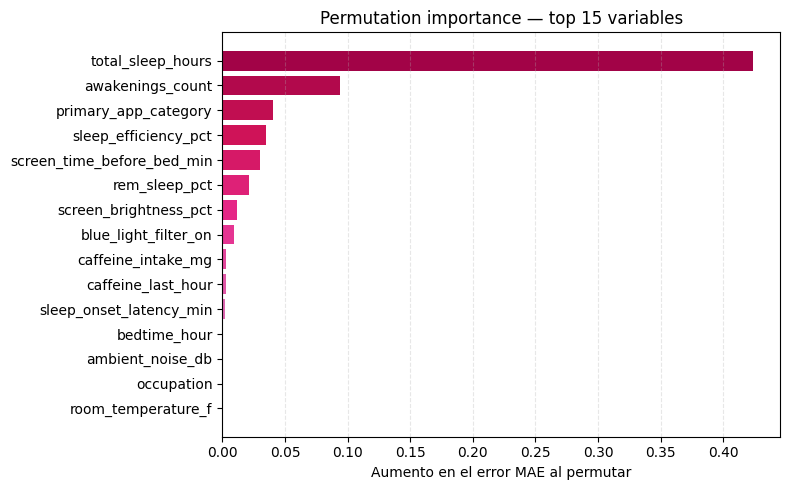

In [27]:
best_cv_name = cv_df.iloc[0]["Modelo"]
best_model = fitted_models[best_cv_name]
print("Modelo con menor MAE medio en CV:", best_cv_name)

perm = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=8,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "variable": X_test.columns,
    "importancia_media": perm.importances_mean,
    "desviacion": perm.importances_std
}).sort_values("importancia_media", ascending=False)

display(importance_df)

plot_df = importance_df.head(15).sort_values("importancia_media")

colores = plt.cm.PuRd(
    np.linspace(0.35, 0.85, len(plot_df))
)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(
    plot_df["variable"],
    plot_df["importancia_media"],
    color=colores
)

ax.set_title("Permutation importance — top 15 variables")
ax.set_xlabel("Aumento en el error MAE al permutar")
ax.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

## 10. Paso 2 — SHAP values (interpretabilidad)

In [14]:
%pip -q install shap

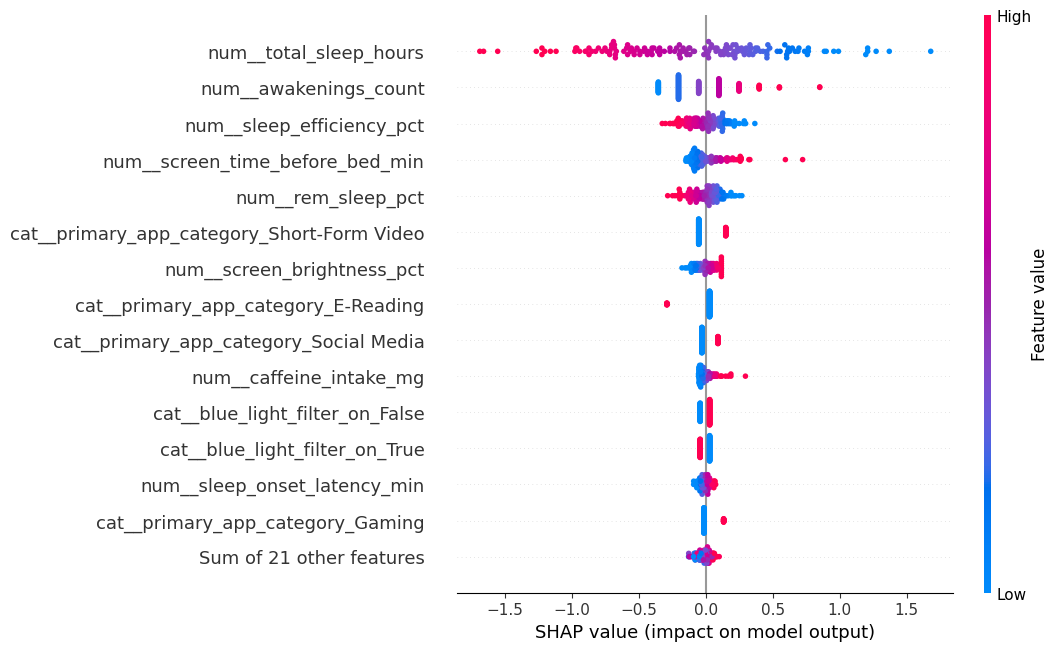

In [15]:

import shap
from scipy import sparse

# 1. Separar el preprocesador y el modelo ya entrenado
preparation = best_model.named_steps["preparation"]
model = best_model.named_steps["model"]

# 2. Seleccionar muestras pequeñas para explicar
X_background = X_train.sample(
    min(100, len(X_train)), random_state=RANDOM_STATE
)
X_explain = X_test.sample(
    min(150, len(X_test)), random_state=RANDOM_STATE
)

# 3. Transformar las variables categóricas y numéricas
# utilizando el preprocesador que ya aprendió del entrenamiento
X_background_transformed = preparation.transform(X_background)
X_explain_transformed = preparation.transform(X_explain)

# 4. Convertir matrices dispersas a matrices numéricas normales
if sparse.issparse(X_background_transformed):
    X_background_transformed = X_background_transformed.toarray()

if sparse.issparse(X_explain_transformed):
    X_explain_transformed = X_explain_transformed.toarray()

# 5. Obtener los nombres de las variables transformadas
feature_names = preparation.get_feature_names_out()

# 6. Crear el explicador SHAP con datos exclusivamente numéricos
explainer = shap.Explainer(
    model.predict,
    X_background_transformed,
    feature_names=feature_names
)

shap_values = explainer(X_explain_transformed)

# 7. Visualizar la importancia e influencia de las variables
shap.plots.beeswarm(shap_values, max_display=15)


## 11. Paso 3 — Revisión de Data Leakage

In [16]:
print("Columnas usadas como predictoras:")
print(X.columns.tolist())
print("\nColumnas excluidas explícitamente:", [c for c in excluded_cols if c in df.columns])
print("¿El target está en X?", TARGET in X.columns)
print("¿user_id está en X?", "user_id" in X.columns)
print("¿sleep_debt_category está en X?", "sleep_debt_category" in X.columns)

# Correlación muy alta puede ser una señal para investigar, no prueba automática de leakage.
if TARGET in df.select_dtypes(include=np.number).columns:
    corr_target = df.select_dtypes(include=np.number).corr()[TARGET].drop(TARGET).abs().sort_values(ascending=False)
    display(corr_target.head(10).to_frame("correlacion_absoluta"))

Columnas usadas como predictoras:
['age', 'gender', 'chronotype', 'occupation', 'bedtime_hour', 'screen_time_before_bed_min', 'primary_app_category', 'screen_brightness_pct', 'blue_light_filter_on', 'caffeine_intake_mg', 'caffeine_last_hour', 'physical_activity_min', 'room_temperature_f', 'ambient_noise_db', 'sleep_onset_latency_min', 'total_sleep_hours', 'rem_sleep_pct', 'deep_sleep_pct', 'awakenings_count', 'sleep_efficiency_pct']

Columnas excluidas explícitamente: ['user_id', 'sleep_debt_category', 'next_day_fatigue_score']
¿El target está en X? False
¿user_id está en X? False
¿sleep_debt_category está en X? False


,correlacion_absoluta
total_sleep_hours,0.688568
sleep_efficiency_pct,0.536935
sleep_onset_latency_min,0.479315
awakenings_count,0.440525
rem_sleep_pct,0.337327
screen_time_before_bed_min,0.336067
age,0.278334
caffeine_intake_mg,0.261541
deep_sleep_pct,0.190759
screen_brightness_pct,0.176128


## 12. Paso 4 — Modelo de árbol de regresión

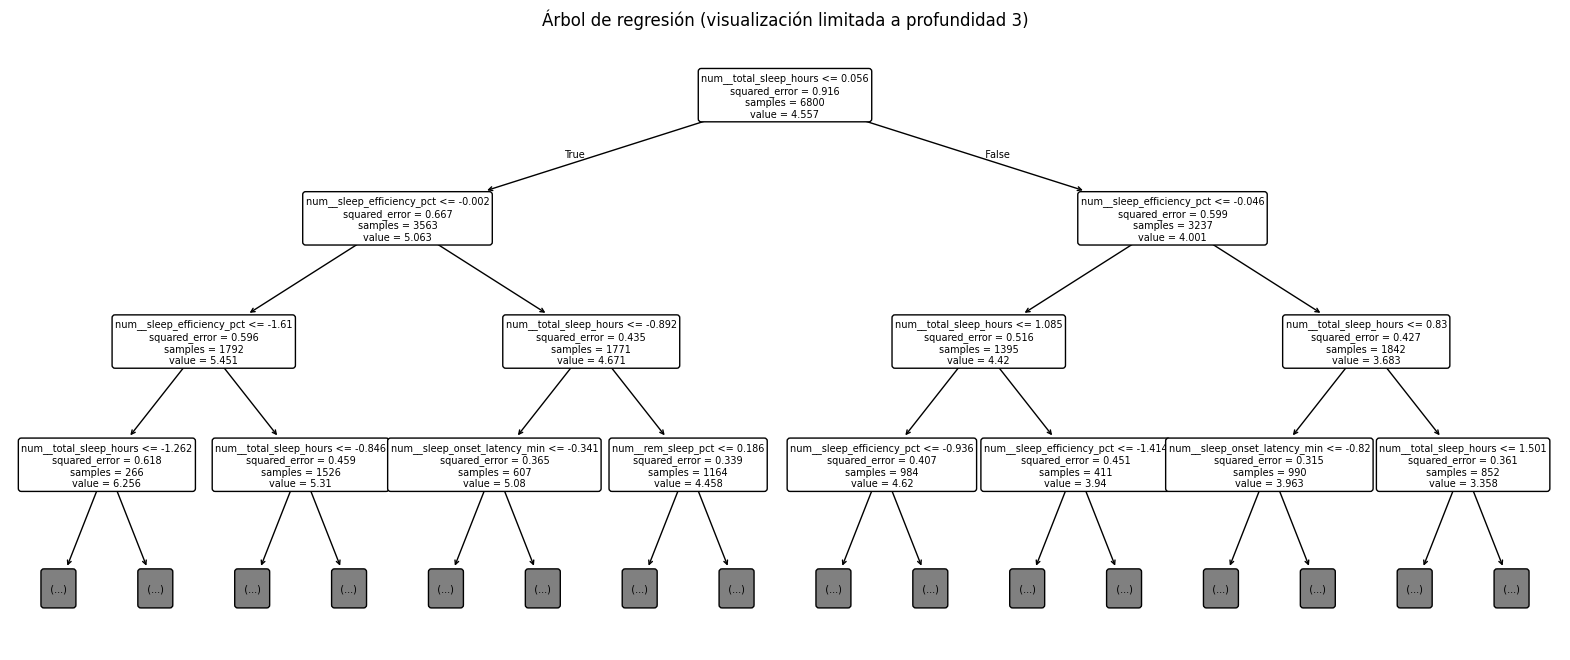

In [17]:
tree_pipe = fitted_models["Árbol de regresión"]
prep_fitted = tree_pipe.named_steps["preparation"]
tree_fitted = tree_pipe.named_steps["model"]
feature_names = prep_fitted.get_feature_names_out()

plt.figure(figsize=(20, 8))
plot_tree(tree_fitted, feature_names=feature_names, filled=False, rounded=True, max_depth=3, fontsize=7)
plt.title("Árbol de regresión (visualización limitada a profundidad 3)")
plt.show()

## 13. Paso 5 — Optuna para ajustar hiperparámetros

In [18]:
%pip -q install optuna

In [19]:
import optuna
from sklearn.model_selection import cross_val_score

def objective(trial):
    model_name = trial.suggest_categorical("modelo", ["DecisionTree", "RandomForest", "GradientBoosting"])
    if model_name == "DecisionTree":
        estimator = DecisionTreeRegressor(
            max_depth=trial.suggest_int("max_depth", 2, 20),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 20),
            random_state=RANDOM_STATE
        )
    elif model_name == "RandomForest":
        estimator = RandomForestRegressor(
            n_estimators=trial.suggest_int("n_estimators", 100, 300, step=100),
            max_depth=trial.suggest_int("max_depth", 3, 25),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 10),
            random_state=RANDOM_STATE, n_jobs=-1
        )
    else:
        estimator = GradientBoostingRegressor(
            n_estimators=trial.suggest_int("n_estimators", 50, 250, step=50),
            learning_rate=trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
            max_depth=trial.suggest_int("max_depth", 2, 5),
            random_state=RANDOM_STATE
        )
    pipe = Pipeline(steps=[("preparation", preprocessor), ("model", estimator)])
    scores = cross_val_score(pipe, X_train, y_train, scoring="neg_mean_absolute_error", cv=cv, n_jobs=-1)
    return -scores.mean()

study = optuna.create_study(direction="minimize", study_name="fatigue_regression_mae")
study.optimize(objective, n_trials=20, show_progress_bar=True)
print("Mejor MAE CV:", study.best_value)
print("Mejores hiperparámetros:", study.best_params)

[I 2026-11-20 00:07:45,978] A new study created in memory with name: fatigue_regression_mae


  0%|          | 0/20 [00:00<?, ?it/s]

[I 2026-11-20 00:08:31,178] Trial 0 finished with value: 0.40714002021201834 and parameters: {'modelo': 'RandomForest', 'n_estimators': 100, 'max_depth': 5, 'min_samples_leaf': 9}. Best is trial 0 with value: 0.40714002021201834.
[I 2026-11-20 00:08:33,842] Trial 1 finished with value: 0.42780461514739426 and parameters: {'modelo': 'DecisionTree', 'max_depth': 13, 'min_samples_leaf': 18}. Best is trial 0 with value: 0.40714002021201834.
[I 2026-11-20 00:09:16,730] Trial 2 finished with value: 0.3625864333435675 and parameters: {'modelo': 'RandomForest', 'n_estimators': 100, 'max_depth': 11, 'min_samples_leaf': 2}. Best is trial 2 with value: 0.3625864333435675.
[I 2026-11-20 00:09:49,462] Trial 3 finished with value: 0.36282342333040724 and parameters: {'modelo': 'RandomForest', 'n_estimators': 100, 'max_depth': 19, 'min_samples_leaf': 4}. Best is trial 2 with value: 0.3625864333435675.
[I 2026-11-20 00:09:50,019] Trial 4 finished with value: 0.4321257890233423 and parameters: {'modelo

### Entrenar el mejor modelo de Optuna y evaluarlo una sola vez en prueba

In [20]:

# Recuperar los mejores parámetros encontrados por Optuna
best_params = study.best_params

print("Modelo seleccionado:", best_params["modelo"])
print("Mejores parámetros:", best_params)

# Crear el modelo con los parámetros correctos
if best_params["modelo"] == "DecisionTree":
    tuned_estimator = DecisionTreeRegressor(
        max_depth=best_params["max_depth"],
        min_samples_leaf=best_params["min_samples_leaf"],
        random_state=RANDOM_STATE
    )

elif best_params["modelo"] == "RandomForest":
    tuned_estimator = RandomForestRegressor(
        n_estimators=best_params["n_estimators"],
        max_depth=best_params["max_depth"],
        min_samples_leaf=best_params["min_samples_leaf"],
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

else:
    tuned_estimator = GradientBoostingRegressor(
        n_estimators=best_params["n_estimators"],
        learning_rate=best_params["learning_rate"],
        max_depth=best_params["max_depth"],
        random_state=RANDOM_STATE
    )

# Crear el pipeline y entrenarlo con los datos de entrenamiento
tuned_model = Pipeline(steps=[
    ("preparation", preprocessor),
    ("model", tuned_estimator)
])

tuned_model.fit(X_train, y_train)

# Evaluar con el conjunto de prueba
tuned_pred = tuned_model.predict(X_test)

tuned_metrics = {
    "Modelo": "Optuna: " + best_params["modelo"],
    "MAE": mean_absolute_error(y_test, tuned_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, tuned_pred)),
    "R2": r2_score(y_test, tuned_pred)
}

print("\nResultados del mejor modelo:")
print(tuned_metrics)


Modelo seleccionado: GradientBoosting
Mejores parámetros: {'modelo': 'GradientBoosting', 'n_estimators': 200, 'learning_rate': 0.09786362593888404, 'max_depth': 2}

Resultados del mejor modelo:
{'Modelo': 'Optuna: GradientBoosting', 'MAE': 0.3357021973499701, 'RMSE': np.float64(0.41722927159326917), 'R2': 0.8032330744058244}


## 13. Paso 6 — Comparación final de modelos

In [21]:
# Seleccionar el mejor modelo usando únicamente la validación cruzada

best_cv = cv_df.iloc[0]

if study.best_value < best_cv["MAE CV promedio"]:
    final_name = "Optuna: " + study.best_params["modelo"]
    final_model = tuned_model
    print("Modelo seleccionado mediante validación cruzada: Optuna")
else:
    final_name = best_cv["Modelo"]
    final_model = fitted_models[final_name]
    print("Modelo seleccionado mediante validación cruzada:", final_name)

# Evaluar el modelo seleccionado con el conjunto de prueba

final_pred = final_model.predict(X_test)

final_results = pd.DataFrame([{
    "Modelo": final_name,
    "MAE": mean_absolute_error(y_test, final_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, final_pred)),
    "R2": r2_score(y_test, final_pred)
}])

display(final_results)

best_final = final_results.iloc[0]

print(f"Modelo seleccionado: {best_final['Modelo']}")
print(f"MAE en prueba: {best_final['MAE']:.4f}")
print(f"RMSE en prueba: {best_final['RMSE']:.4f}")
print(f"R² en prueba: {best_final['R2']:.4f}")

Modelo seleccionado mediante validación cruzada: Regresión lineal


,Modelo,MAE,RMSE,R2
0,Regresión lineal,0.328537,0.406356,0.813355


Modelo seleccionado: Regresión lineal
MAE en prueba: 0.3285
RMSE en prueba: 0.4064
R² en prueba: 0.8134


## 14. Gráfico de valores reales vs. predichos

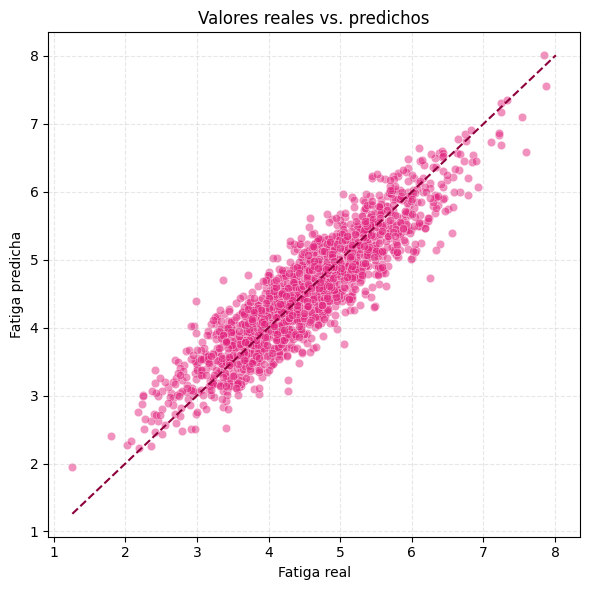

In [28]:
# Usar el modelo con menor MAE de la tabla final para visualizar el ajuste
final_name = best_final["Modelo"]

if final_name.startswith("Optuna:"):
    final_model = tuned_model
else:
    final_model = fitted_models[final_name]

final_pred = final_model.predict(X_test)

fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(
    y_test,
    final_pred,
    alpha=0.5,
    color=plt.cm.PuRd(0.65),
    edgecolors="white",
    linewidths=0.4
)

lims = [min(y_test.min(), final_pred.min()), max(y_test.max(), final_pred.max())]
ax.plot(lims, lims, linestyle="--", color=plt.cm.PuRd(0.9), linewidth=1.5)

ax.set_xlabel("Fatiga real")
ax.set_ylabel("Fatiga predicha")
ax.set_title("Valores reales vs. predichos")
ax.grid(linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

## 15. Conclusiones finales

La fatiga del día siguiente está estrechamente relacionada con las características del descanso nocturno, especialmente con la duración total del sueño, su eficiencia y las interrupciones durante la noche. También se observan diferencias asociadas a los hábitos digitales y al cronotipo, que aportan información complementaria para comprender este fenómeno. Los resultados del modelo de regresión lineal, con un R² de 81,34 % y un MAE de 0,3285, muestran que es posible estimar la puntuación de fatiga con un desempeño predictivo favorable. En este sentido, el principal hallazgo es que no solo importa cuánto dormimos, sino también cómo dormimos, pues las características del descanso contienen información clave para comprender y anticipar la fatiga del día siguiente.